# 01 · Exploración de los datos M5 (Walmart)

**Contexto:** el dataset de la competencia *M5 Forecasting* tiene las ventas diarias de unidades de 3.049 productos en 10 tiendas de Walmart de tres estados de EE. UU. (California, Texas y Wisconsin), junto con un calendario de eventos y los precios semanales. Cada combinación de producto y tienda es una **serie de tiempo**: en total, 30.490 series.

**Objetivo de este notebook:** entender cómo son los datos antes de modelar, y fijar el **protocolo de evaluación** que se usará en todos los modelos del proyecto.

**Preguntas que responde este notebook**
1. ¿Cómo está organizado el dataset y qué período cubre?
2. ¿Qué estacionalidad y qué eventos afectan las ventas?
3. ¿Qué tan intermitente es la demanda (muchos días sin ventas)?
4. ¿Todas las series empiezan al mismo tiempo?
5. ¿Qué relación hay entre el precio y las ventas?
6. ¿Cómo se va a evaluar cada modelo?

## 1. Setup

In [1]:
import os
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = os.path.abspath("..")
sys.path.insert(0, ROOT)

from src.data import (
    ensure_m5, load_calendar, load_prices, load_sales, day_columns,
    sample_series, to_long, SEED,
)

plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 30)

## 2. Carga de datos

Se leen tres archivos: el **calendario** (fecha, día de la semana, eventos y días de beneficio social SNAP), los **precios** semanales de cada producto en cada tienda y las **ventas diarias** en formato ancho (una columna por día). Se usa la versión `evaluation` de las ventas (hasta el día 1.941) y, si no está disponible, la `validation` (hasta el día 1.913); la primera vez, `ensure_m5()` descomprime o descarga los archivos.

In [2]:
carpeta = ensure_m5()
calendario = load_calendar(carpeta)
precios = load_prices(carpeta)
ventas = load_sales(carpeta)

dias = day_columns(ventas)
Y = ventas[dias].to_numpy()

print("Series:", len(ventas), "| días con ventas:", len(dias))
if len(dias) < 1941:
    print("AVISO: hay menos de 1.941 días (versión validation); las ventanas del protocolo se calculan con el último día disponible.")
print("Filas de precios:", len(precios), "| días del calendario:", len(calendario))
ventas.iloc[:3, :10]

Series: 30490 | días con ventas: 1941
Filas de precios: 6841121 | días del calendario: 1969


,id,item_id,dept_id,cat_id,store_id,state_id,d_1,d_2,d_3,d_4
0,HOBBIES_1_001_CA_1_evaluation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0
1,HOBBIES_1_002_CA_1_evaluation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0
2,HOBBIES_1_003_CA_1_evaluation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0


### 2.1 Jerarquía y período

Las series se pueden agrupar por tienda, estado, departamento y categoría. Esa jerarquía es útil para entender cómo se reparten las ventas, aunque en este proyecto se pronostica a nivel de cada producto y tienda.

In [3]:
jerarquia = pd.Series({
    "series (producto × tienda)": len(ventas),
    "productos": ventas["item_id"].nunique(),
    "departamentos": ventas["dept_id"].nunique(),
    "categorías": ventas["cat_id"].nunique(),
    "tiendas": ventas["store_id"].nunique(),
    "estados": ventas["state_id"].nunique(),
})
print(jerarquia.to_string())

fechas = calendario.set_index("d").loc[dias, "date"]
print(f"\nPrimer día: {fechas.iloc[0].date()} | último día con ventas: {fechas.iloc[-1].date()} | días: {len(dias)}")

pd.crosstab(ventas["cat_id"], ventas["store_id"])

series (producto × tienda)    30490
productos                      3049
departamentos                     7
categorías                        3
tiendas                          10
estados                           3

Primer día: 2011-01-29 | último día con ventas: 2016-05-22 | días: 1941


store_id,CA_1,CA_2,CA_3,CA_4,TX_1,TX_2,TX_3,WI_1,WI_2,WI_3
cat_id,,,,,,,,,,
HOBBIES,565,565,565,565,565,565,565,565,565,565
HOUSEHOLD,1047,1047,1047,1047,1047,1047,1047,1047,1047,1047
FOODS,1437,1437,1437,1437,1437,1437,1437,1437,1437,1437


## 3. Ventas totales en el tiempo

Se suma la venta de todas las series para cada día, y se muestra la media móvil de 28 días, que elimina el efecto del día de la semana y deja ver la tendencia y la estacionalidad anual.

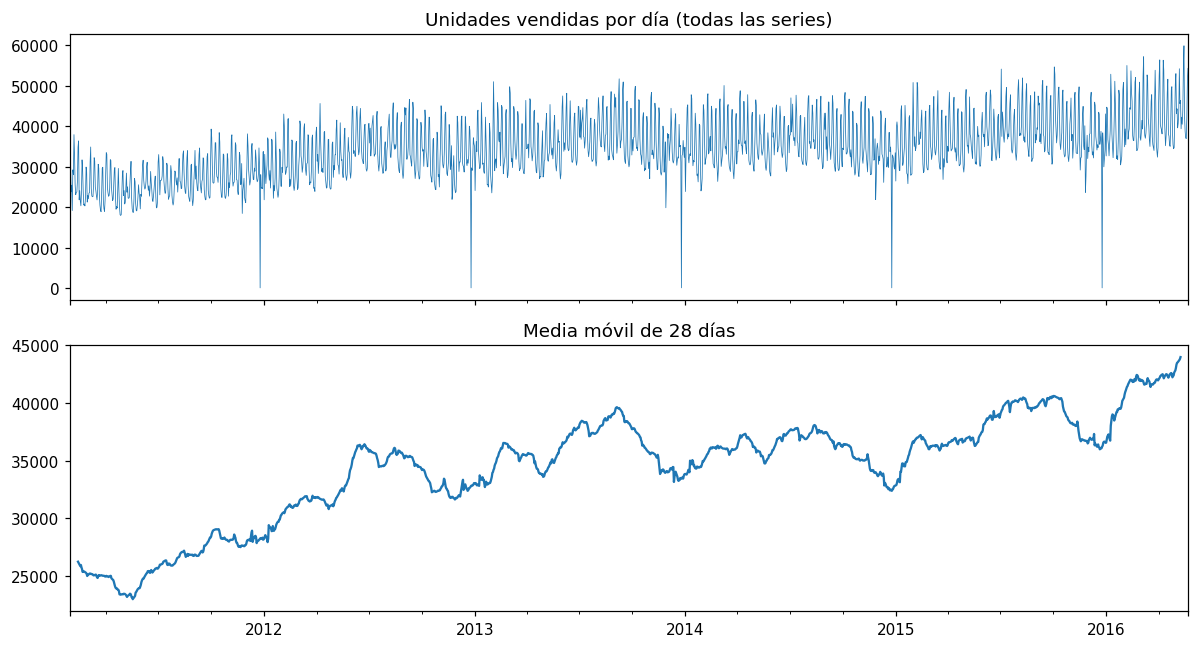

Días con ventas muy bajas (menos del 30 % de la mediana):
            unidades dia_semana
2011-12-25        13     Sunday
2012-12-25        11    Tuesday
2013-12-25        20  Wednesday
2014-12-25        20   Thursday
2015-12-25        14     Friday


In [4]:
fechas_d = pd.to_datetime(fechas.to_numpy())
total_diario = pd.Series(Y.sum(axis=0), index=fechas_d)

fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
total_diario.plot(ax=axes[0], linewidth=0.5)
axes[0].set_title("Unidades vendidas por día (todas las series)")
total_diario.rolling(28, center=True).mean().plot(ax=axes[1])
axes[1].set_title("Media móvil de 28 días")
plt.tight_layout()
plt.show()

cierres = total_diario[total_diario < 0.3 * total_diario.median()]
print("Días con ventas muy bajas (menos del 30 % de la mediana):")
print(cierres.to_frame("unidades").assign(dia_semana=cierres.index.day_name()))

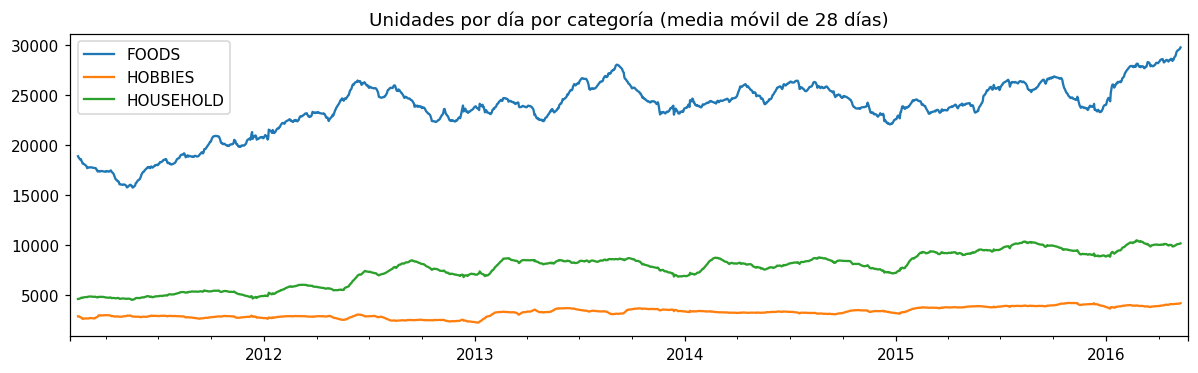

Participación en las unidades vendidas: {'FOODS': 0.686, 'HOBBIES': 0.093, 'HOUSEHOLD': 0.221}


In [5]:
por_categoria = pd.DataFrame(
    {cat: Y[(ventas["cat_id"] == cat).to_numpy()].sum(axis=0) for cat in sorted(ventas["cat_id"].unique())},
    index=fechas_d,
)
ax = por_categoria.rolling(28, center=True).mean().plot(figsize=(11, 3.5))
ax.set_title("Unidades por día por categoría (media móvil de 28 días)")
plt.tight_layout()
plt.show()

participacion = (por_categoria.sum() / por_categoria.sum().sum()).round(3)
print("Participación en las unidades vendidas:", participacion.to_dict())

### 3.1 Estacionalidad semanal y anual

El **índice semanal** compara las ventas de cada día de la semana con el promedio diario. El **índice mensual** hace lo mismo con cada mes del año, y está calculado sobre los días disponibles, por lo que los años incompletos influyen un poco.

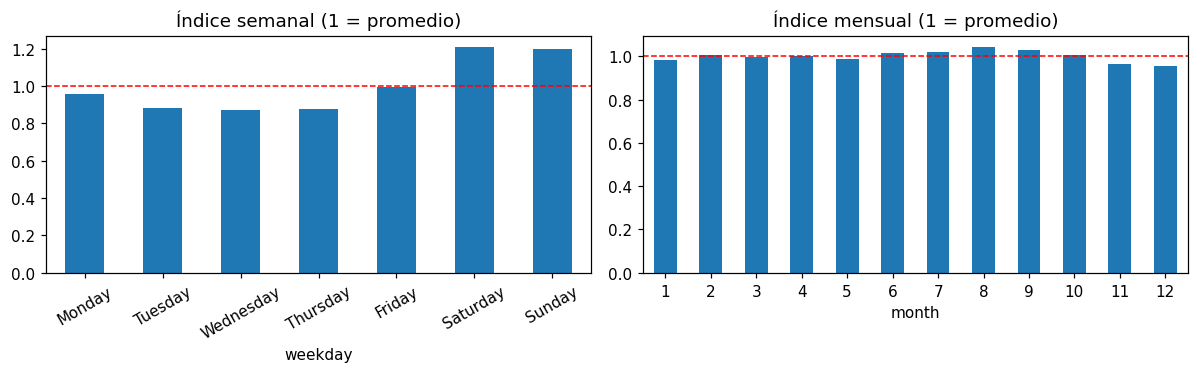

Índice semanal:
weekday
Monday       0.957
Tuesday      0.885
Wednesday    0.874
Thursday     0.879
Friday       0.996
Saturday     1.210
Sunday       1.198

Índice mensual (mes 1 = enero):
month
1     0.981
2     1.005
3     0.996
4     0.999
5     0.989
6     1.015
7     1.019
8     1.043
9     1.029
10    1.007
11    0.965
12    0.956


In [6]:
cal = calendario.set_index("d").loc[dias].copy()
cal["total"] = total_diario.to_numpy()

indice_semana = cal.groupby("weekday")["total"].mean() / cal["total"].mean()
orden = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
indice_semana = indice_semana.reindex(orden)

indice_mes = cal.groupby("month")["total"].mean() / cal["total"].mean()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
indice_semana.plot.bar(ax=axes[0], rot=30)
axes[0].axhline(1, color="red", linestyle="--", linewidth=1)
axes[0].set_title("Índice semanal (1 = promedio)")
indice_mes.plot.bar(ax=axes[1], rot=0)
axes[1].axhline(1, color="red", linestyle="--", linewidth=1)
axes[1].set_title("Índice mensual (1 = promedio)")
plt.tight_layout()
plt.show()

print("Índice semanal:")
print(indice_semana.round(3).to_string())
print("\nÍndice mensual (mes 1 = enero):")
print(indice_mes.round(3).to_string())

## 4. Eventos y días SNAP

Para medir el efecto de un evento sin confundirlo con la tendencia y el día de la semana, se calcula la **venta relativa**: el total del día dividido por la media móvil de 28 días, y luego corregido por el índice semanal. Un valor de 1 indica un día normal. Es una descripción, no un efecto causal: un evento puede coincidir con otras cosas, como una temporada.

In [7]:
rel = cal["total"] / cal["total"].rolling(28, center=True).mean()
cal["rel"] = rel / rel.groupby(cal["weekday"]).transform("mean")

evento = cal[cal["event_name_1"].notna()]
por_tipo = evento.groupby("event_type_1")["rel"].agg(["count", "mean"]).round(3)
print("Venta relativa por tipo de evento (1 = día normal):")
print(por_tipo)

por_evento = evento.groupby("event_name_1")["rel"].agg(["count", "mean"])
por_evento = por_evento[por_evento["count"] >= 4].sort_values("mean").round(3)
print("\nEventos con menor venta relativa:")
print(por_evento.head(5))
print("\nEventos con mayor venta relativa:")
print(por_evento.tail(5))

Venta relativa por tipo de evento (1 = día normal):
              count   mean
event_type_1              
Cultural         37  0.931
National         51  0.896
Religious        54  1.013
Sporting         15  1.007

Eventos con menor venta relativa:
              count   mean
event_name_1              
Christmas         5  0.001
Thanksgiving      5  0.734
NewYear           5  0.817
Mother's day      6  0.875
Father's day      4  0.885

Eventos con mayor venta relativa:
                   count   mean
event_name_1                   
NBAFinalsStart         5  1.047
VeteransDay            5  1.057
OrthodoxChristmas      5  1.060
Chanukah End           5  1.063
LaborDay               5  1.226


Los **días SNAP** son días en que los beneficiarios del programa de asistencia alimentaria pueden usar el beneficio en las tiendas de cada estado. Se compara la venta relativa de las tiendas de cada estado en los días SNAP y en los que no lo son.

In [8]:
filas = []
for estado in sorted(ventas["state_id"].unique()):
    total_e = pd.Series(Y[(ventas["state_id"] == estado).to_numpy()].sum(axis=0), index=cal.index)
    r = total_e / total_e.rolling(28, center=True).mean()
    r = r / r.groupby(cal["weekday"]).transform("mean")
    snap = cal[f"snap_{estado}"] == 1
    filas.append({"estado": estado, "días_snap_%": 100 * snap.mean(),
                  "venta_relativa_snap": r[snap].mean(), "venta_relativa_sin_snap": r[~snap].mean()})
pd.DataFrame(filas).round(3)

,estado,días_snap_%,venta_relativa_snap,venta_relativa_sin_snap
0,CA,32.973,1.054,0.973
1,TX,32.973,1.073,0.964
2,WI,32.973,1.131,0.936


## 5. Muestra de series para el proyecto

Modelar las 30.490 series exigiría mucho más cómputo del que se dispone en una CPU. Por eso, los modelos del proyecto se entrenan y evalúan sobre una **muestra reproducible de 60 series por tienda (600 en total)**, elegidas al azar con semilla fija. Se comprueba que la muestra se parezca al conjunto completo.

In [9]:
muestra = sample_series(ventas, n_per_store=60, seed=SEED)
Y_m = muestra[dias].to_numpy()

comparacion = pd.DataFrame({
    "categoría_total_%": 100 * ventas["cat_id"].value_counts(normalize=True),
    "categoría_muestra_%": 100 * muestra["cat_id"].value_counts(normalize=True),
}).round(1)
print(comparacion)
print()
print(f"Proporción de días sin ventas — total: {(Y == 0).mean():.3f} | muestra: {(Y_m == 0).mean():.3f}")
print(f"Venta media por serie y día — total: {Y.mean():.3f} | muestra: {Y_m.mean():.3f}")
print("Series en la muestra:", len(muestra))

           categoría_total_%  categoría_muestra_%
cat_id                                           
FOODS                   47.1                 48.0
HOUSEHOLD               34.3                 33.5
HOBBIES                 18.5                 18.5

Proporción de días sin ventas — total: 0.680 | muestra: 0.682
Venta media por serie y día — total: 1.131 | muestra: 1.122
Series en la muestra: 600


## 6. Intermitencia de la demanda

Muchas series tienen **demanda intermitente**: la mayoría de los días no se vende nada, y los días con ventas, las cantidades son chicas. Esto dificulta el pronóstico y es la razón de que las métricas usuales, como el error porcentual, no sean adecuadas (se dividiría por cero).

Se clasifica cada serie con el esquema de Syntetos y Boylan (2005), a partir de dos medidas calculadas desde la primera venta:

- **ADI** (intervalo medio entre demandas): cuántos días pasan, en promedio, entre un día con ventas y el siguiente.
- **CV²**: cuánto varían las cantidades vendidas, relativo a su media (coeficiente de variación al cuadrado), considerando solo los días con ventas.

Con los umbrales habituales de ADI = 1,32 y CV² = 0,49, las series se dividen en cuatro tipos: **suave** (ventas frecuentes y regulares), **errática** (frecuentes, pero con cantidades variables), **intermitente** (esporádicas, con cantidades regulares) y **irregular** (esporádicas y con cantidades muy variables).

In [10]:
inicio = np.where((Y > 0).any(axis=1), (Y > 0).argmax(axis=1), Y.shape[1])

adi = np.full(len(Y), np.nan)
cv2 = np.full(len(Y), np.nan)
for i in range(len(Y)):
    y = Y[i, inicio[i]:]
    nz = y[y > 0]
    if len(nz) > 0:
        adi[i] = len(y) / len(nz)
        cv2[i] = (nz.std() / nz.mean()) ** 2

tipo = np.select(
    [np.isnan(adi), (adi < 1.32) & (cv2 < 0.49), (adi < 1.32), (cv2 < 0.49)],
    ["sin ventas", "suave", "errática", "intermitente"],
    default="irregular",
)

unidades = Y.sum(axis=1)
tabla_tipo = pd.DataFrame({"series": pd.Series(tipo).value_counts()})
tabla_tipo["series_%"] = 100 * tabla_tipo["series"] / len(Y)
tabla_tipo["unidades_%"] = 100 * pd.Series(unidades).groupby(tipo).sum().reindex(tabla_tipo.index) / unidades.sum()
tabla_tipo.round(1)

,series,series_%,unidades_%
intermitente,22155,72.7,33.8
irregular,5572,18.3,23.8
suave,1903,6.2,28.6
errática,860,2.8,13.8


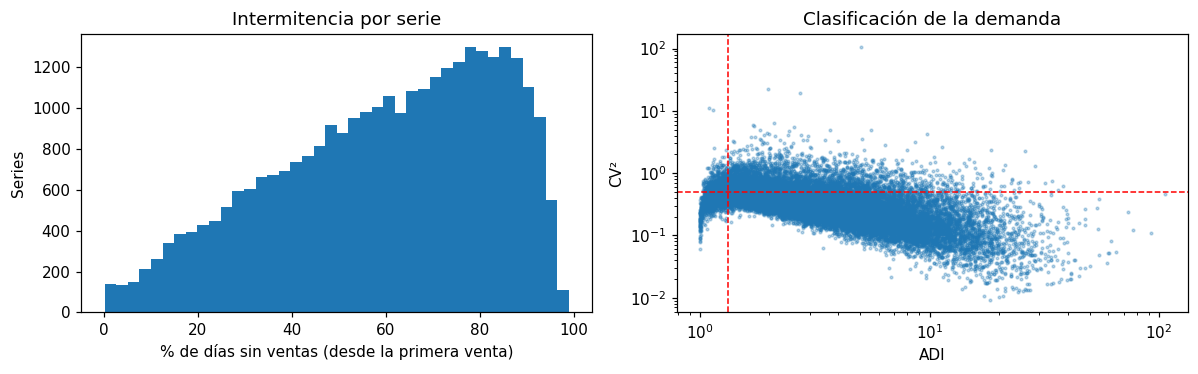

Proporción global de días sin ventas: 68.0%
Mediana del % de días sin ventas por serie (desde la primera venta): 63.3 %


In [11]:
dias_activos = Y.shape[1] - inicio
pct_ceros = 1 - (Y > 0).sum(axis=1) / np.maximum(dias_activos, 1)
validas = dias_activos > 0

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].hist(100 * pct_ceros[validas], bins=40)
axes[0].set_xlabel("% de días sin ventas (desde la primera venta)")
axes[0].set_ylabel("Series")
axes[0].set_title("Intermitencia por serie")
axes[1].scatter(adi, cv2, s=3, alpha=0.3)
axes[1].axvline(1.32, color="red", linestyle="--", linewidth=1)
axes[1].axhline(0.49, color="red", linestyle="--", linewidth=1)
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_xlabel("ADI")
axes[1].set_ylabel("CV²")
axes[1].set_title("Clasificación de la demanda")
plt.tight_layout()
plt.show()

print(f"Proporción global de días sin ventas: {(Y == 0).mean():.1%}")
print(f"Mediana del % de días sin ventas por serie (desde la primera venta): {100 * np.median(pct_ceros[validas]):.1f} %")

## 7. Series que empiezan tarde

No todas las series tienen historia completa: muchos productos se incorporan a una tienda después del primer día, y hasta entonces sus ventas figuran como cero. Esos ceros iniciales **no son demanda nula**, son productos que todavía no se vendían, y si se tratan como demanda real distorsionan los modelos y las métricas. Por eso la métrica del proyecto cuenta el pasado desde la primera venta.

Series que empiezan después del primer día: 23511 (77.1%)
Series con al menos 1 año de ceros iniciales: 13420 (44.0%)
Series sin ninguna venta: 0


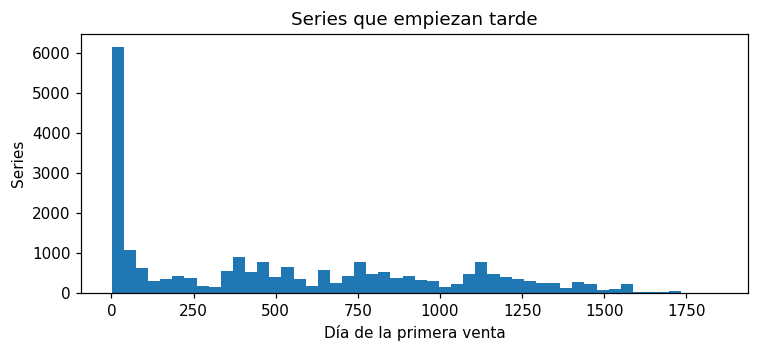

In [12]:
tarde = inicio > 0
print(f"Series que empiezan después del primer día: {tarde.sum()} ({tarde.mean():.1%})")
print(f"Series con al menos 1 año de ceros iniciales: {(inicio > 365).sum()} ({(inicio > 365).mean():.1%})")
print(f"Series sin ninguna venta: {(inicio == Y.shape[1]).sum()}")

fig, ax = plt.subplots(figsize=(7, 3.3))
ax.hist(inicio[tarde], bins=50)
ax.set_xlabel("Día de la primera venta")
ax.set_ylabel("Series")
ax.set_title("Series que empiezan tarde")
plt.tight_layout()
plt.show()

## 8. Precios y ventas

Los precios cambian poco, y las promociones pueden verse como bajas temporales. Primero se mide cuánto varían los precios, y luego, de forma descriptiva, cómo se relacionan con las ventas en la muestra: para cada serie y semana, el precio relativo (precio de la semana dividido por el precio mediano de esa serie) y las ventas relativas (ventas de la semana divididas por el promedio semanal de esa serie).

Es una descripción y no una elasticidad: los descuentos suelen coincidir con eventos y temporadas, por lo que parte de la relación puede deberse a eso.

In [13]:
pares = muestra[["item_id", "store_id"]].astype(str).drop_duplicates()
precios_m = precios.assign(item_id=precios["item_id"].astype(str), store_id=precios["store_id"].astype(str)).merge(pares)

g = precios_m.groupby(["store_id", "item_id"])["sell_price"]
cambia = g.nunique() > 1
variacion = precios_m.sort_values("wm_yr_wk").groupby(["store_id", "item_id"])["sell_price"].pct_change().dropna()
print(f"Series de la muestra con más de un precio: {cambia.mean():.1%}")
print(f"Semanas en que el precio cambia: {(variacion != 0).mean():.1%}")
print(f"Entre los cambios, mediana del cambio absoluto: {100 * variacion[variacion != 0].abs().median():.1f} %")

Series de la muestra con más de un precio: 73.2%
Semanas en que el precio cambia: 1.2%
Entre los cambios, mediana del cambio absoluto: 8.4 %


In [14]:
largo = to_long(muestra, calendario, precios)
sem = largo.groupby(["id", "wm_yr_wk"], observed=True).agg(
    ventas=("ventas", "sum"), precio=("sell_price", "first"), n_dias=("ventas", "size")
).reset_index()
sem = sem[(sem["n_dias"] == 7) & sem["precio"].notna()].copy()

sem["precio_rel"] = sem["precio"] / sem.groupby("id", observed=True)["precio"].transform("median")
sem["ventas_rel"] = sem["ventas"] / sem.groupby("id", observed=True)["ventas"].transform("mean")

grupos = pd.cut(sem["precio_rel"], [0, 0.90, 0.97, 1.03, np.inf],
                labels=["baja > 10 %", "baja 3-10 %", "habitual (±3 %)", "sube > 3 %"])
tabla = sem.groupby(grupos, observed=True).agg(semanas=("ventas_rel", "size"), ventas_relativas=("ventas_rel", "mean"))
tabla["semanas_%"] = 100 * tabla["semanas"] / tabla["semanas"].sum()
tabla.round(3)

,semanas,ventas_relativas,semanas_%
precio_rel,,,
baja > 10 %,5473,1.251,4.083
baja 3-10 %,9138,1.145,6.818
habitual (±3 %),104276,0.983,77.797
sube > 3 %,15149,0.936,11.302


## 9. Protocolo de evaluación

Se define **antes de entrenar ningún modelo**, para que todos se comparen en las mismas condiciones y no se ajuste la evaluación a los resultados.

**Datos:** la muestra de 600 series (60 por tienda, semilla 42) sobre las ventas disponibles.

**Horizonte y ventanas:** se pronostican **28 días**, como en la competencia, desde un origen determinado y sin información posterior a él. Se usan las dos últimas ventanas de 28 días disponibles:
- **Validación:** la penúltima ventana. Sirve para comparar variantes de modelos y elegir hiperparámetros.
- **Test:** la última ventana. Se usa **una sola vez**, al final, con el modelo ya elegido y reentrenado con los datos hasta el origen del test.

Con la versión `evaluation` (1.941 días), la validación son los días 1.886 a 1.913 y el test, los días 1.914 a 1.941; con la versión `validation` (1.913 días), la validación son los días 1.858 a 1.885 y el test, los días 1.886 a 1.913. La celda siguiente calcula las ventanas a partir de los datos cargados.

Los baselines y el modelo estadístico, que no tienen hiperparámetros que elegir en esta etapa, se evalúan en ambas ventanas.

In [15]:
HORIZONTE = 28
T = len(dias)  # último día disponible

ventanas = {
    "validación": (T - 2 * HORIZONTE + 1, T - HORIZONTE),
    "test": (T - HORIZONTE + 1, T),
}
for nombre, (ini, fin) in ventanas.items():
    print(f"{nombre:>10}: días {ini} a {fin} ({fechas_d[ini - 1].date()} a {fechas_d[fin - 1].date()}) | origen en el día {ini - 1}")

validación: días 1886 a 1913 (2016-03-28 a 2016-04-24) | origen en el día 1885
      test: días 1914 a 1941 (2016-04-25 a 2016-05-22) | origen en el día 1913


**Qué se conoce de antemano:** el calendario y los precios de los 28 días a pronosticar. En M5 los precios futuros se publican con anticipación, y así se asume en este proyecto. Las ventas posteriores al origen no se usan.

**Métricas (solo dos):**
- **RMSSE (error escalado):** error cuadrático medio del pronóstico, dividido por el error cuadrático medio de un pronóstico ingenuo (repetir el día anterior) en el pasado de la misma serie, y con raíz cuadrada. Se cuenta desde la primera venta. **Un valor menor a 1 significa que el modelo se equivoca menos que el ingenuo *en el pasado de esa serie*; no es una comparación directa con el ingenuo en el período a pronosticar.** Es adimensional, por lo que se pueden promediar series de distinta escala, y funciona con demanda intermitente. Se reporta el **promedio simple** entre series (no ponderado por ingresos, como el WRMSSE de la competencia).
- **MAE (error absoluto medio):** diferencia absoluta promedio entre ventas reales y pronosticadas, en unidades por serie y día. Es fácil de interpretar, pero depende de la escala de las series.

Las series sin ventas antes del origen (o sin variación) no tienen escala y quedan fuera del RMSSE; se informa cuántas son. El MAE se calcula sobre todas las series.

Los dos errores se reportan juntos porque se complementan: el RMSSE penaliza más los errores grandes y permite comparar series distintas, y el MAE indica el error típico en unidades.

## 10. Conclusiones

- **Estructura:** 30.490 series (3.049 productos en 10 tiendas de 3 estados), con ventas diarias del 29 de enero de 2011 al 22 de mayo de 2016 (1.941 días). Todas las tiendas tienen el mismo surtido: 1.437 productos de FOODS, 1.047 de HOUSEHOLD y 565 de HOBBIES. FOODS concentra el 68,6 % de las unidades vendidas, HOUSEHOLD el 22,1 % y HOBBIES el 9,3 %.
- **Tendencia y escala por categoría:** en la media móvil de 28 días, las ventas de las tres categorías oscilan y parecen crecer con el tiempo. FOODS se mueve entre unas 20.000 y 30.000 unidades por día, HOUSEHOLD entre 5.000 y 10.000 y HOBBIES entre 2.000 y 4.000 (valores aproximados, leídos del gráfico).
- **Estacionalidad semanal fuerte:** el sábado (1,21) y el domingo (1,20) se vende alrededor de un 20 % más que el promedio, y de martes a jueves (0,87 a 0,89) alrededor de un 12 % menos. Entre el mejor y el peor día la diferencia es de unos 38 %. Es el patrón más marcado de los datos y los modelos tienen que capturarlo.
- **Estacionalidad anual débil y tendencia creciente:** el índice mensual va de 0,96 (diciembre) a 1,04 (agosto). No está corregido por la tendencia: en las tres categorías las ventas diarias parecen crecer con el tiempo, por lo que parte de esa variación puede reflejar el crecimiento y no la estacionalidad.
- **Eventos:** el 25 de diciembre las tiendas prácticamente no venden (entre 11 y 20 unidades en total entre las 30.490 series), lo que es un cierre y no una demanda baja. Entre los eventos con al menos 4 ocurrencias, Acción de Gracias (0,73), Año Nuevo (0,82) y el Día de la Madre (0,88) venden menos que un día normal, y el Día del Trabajo (1,23) vende más. Los promedios por tipo (nacionales 0,90 con 51 eventos, culturales 0,93 con 37, religiosos 1,01 con 54 y deportivos 1,01 con 15) mezclan eventos muy distintos; en particular, el cierre del 25 de diciembre puede arrastrar hacia abajo el promedio del tipo al que pertenece, por lo que son menos informativos que los valores por evento. Cada evento tiene pocas ocurrencias (4 a 6), así que los valores individuales son ruidosos.
- **Días SNAP:** en los tres estados el 33 % de los días son SNAP, y esos días se vende más: la venta relativa es 1,08 veces la de los días sin SNAP en California (1,054 contra 0,973), 1,11 en Texas y 1,21 en Wisconsin. Es una diferencia descriptiva que no separa el efecto del beneficio del efecto de la época del mes en que cae.
- **Intermitencia:** el 68,0 % de las observaciones diarias son cero, y la mediana de días sin ventas por serie, contados desde su primera venta, es 63,3 %. Según la clasificación de Syntetos y Boylan, el 72,7 % de las series es intermitente y el 18,3 % irregular: el 91 % tiene una demanda esporádica, y esas series reúnen el 57,6 % de las unidades. Solo el 6,2 % es suave y el 2,8 % errática, pero concentran el 42,4 % de las unidades.
- **Series que empiezan tarde:** el 77,1 % de las series tiene su primera venta después del primer día, y el 44,0 % tiene al menos un año de ceros iniciales. Ninguna serie está completamente vacía. Esos ceros no son demanda nula; por eso el RMSSE cuenta el pasado desde la primera venta, y por eso la antigüedad de cada serie es información relevante para los modelos.
- **Precios:** el 73,2 % de las series de la muestra cambia de precio alguna vez, pero el precio cambia en solo el 1,2 % de las semanas (mediana del cambio absoluto: 8,4 %). Las semanas con una baja de precio de más de 10 % (4,1 % de las semanas) tienen ventas 25 % superiores a lo habitual de la serie (1,25), las de baja de 3 a 10 % (6,8 % de las semanas) tienen 15 % más (1,15) y las semanas con una suba de más de 3 % (11,3 %) tienen 6 % menos (0,94). El 77,8 % de las semanas tiene un precio habitual (dentro de ±3 % de la mediana de la serie). Es una relación descriptiva y no causal: los descuentos coinciden con eventos y con la antigüedad de cada producto.
- **Representatividad de la muestra:** las 600 series reproducen la composición por categoría (FOODS 48,0 % contra 47,1 % en el total) y la intermitencia (68,2 % de días sin ventas contra 68,0 %).
- **Implicaciones para el modelado:**
  - Los modelos tienen que usar el día de la semana. El calendario (con una marca del 25 de diciembre), los días SNAP y los precios pueden aportar información adicional.
  - Como las ventas parecen crecer con el tiempo, el historial lejano describe peor la demanda actual: conviene que los modelos den más peso a lo reciente (medias móviles cortas, rezagos y antigüedad de la serie).
  - Con una demanda tan esporádica, el MAE y el RMSSE pueden ordenar los modelos de forma distinta: el MAE se minimiza pronosticando la mediana de cada serie (que en muchas es cero) y el RMSSE, basado en errores al cuadrado, pronosticando el promedio. Los dos errores se leerán juntos.
  - Las ventanas de evaluación son la validación (del 28 de marzo al 24 de abril de 2016, días 1.886 a 1.913) y el test (del 25 de abril al 22 de mayo, días 1.914 a 1.941). No incluyen los feriados de mayor impacto (Navidad, Acción de Gracias ni Año Nuevo): la validación no tiene ningún evento y el test tiene cuatro menores (Pesach End, Pascua ortodoxa, Cinco de Mayo y el Día de la Madre). Por eso los eventos pesarán poco en las métricas, aunque sí importan al entrenar.
- **Limitaciones:** las estadísticas de este notebook usan todos los días disponibles, incluidas las ventanas de validación y test. No se usan para ajustar ningún modelo (los modelos solo ven datos anteriores a cada origen), pero la clasificación por tipo de demanda de este notebook puede diferir de la que se calcula solo con el historial anterior a cada origen, como en los notebooks siguientes. Las tablas de eventos, SNAP y precios son descriptivas y no establecen relaciones causales, y las cifras leídas de gráficos son aproximadas.